===阅读记录原始数据概况===
<class 'pandas.DataFrame'>
RangeIndex: 2320 entries, 0 to 2319
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   record_id        2320 non-null   int64
 1   user_id          2320 non-null   int64
 2   novel_id         2320 non-null   int64
 3   read_start_time  2320 non-null   str  
 4   read_duration    2320 non-null   int64
dtypes: int64(4), str(1)
memory usage: 133.8 KB
None
异常阅读时长统计：
read_duration
-10       76
 0       168
 31        1
 32        2
 34        1
        ... 
 3592      1
 3594      1
 3595      1
 3598      1
 3600      1
Name: count, Length: 1512, dtype: int64
✅ 清洗完成，已保存清洗后csv


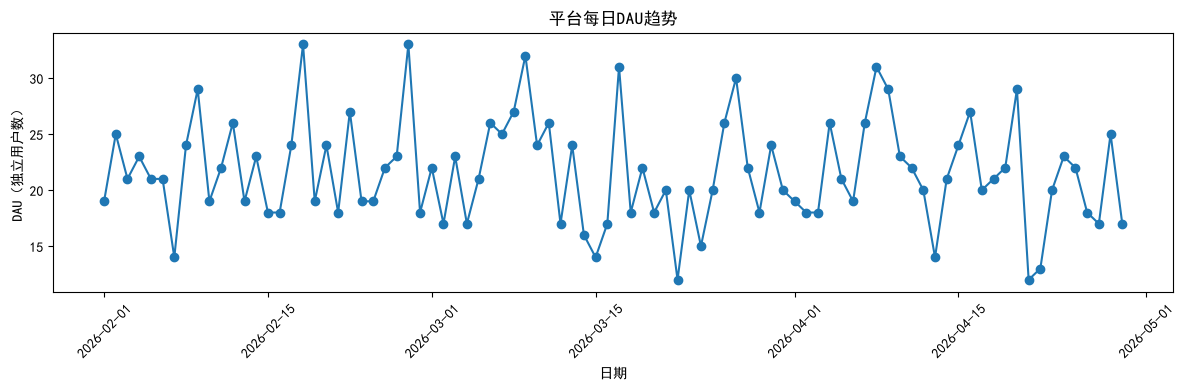

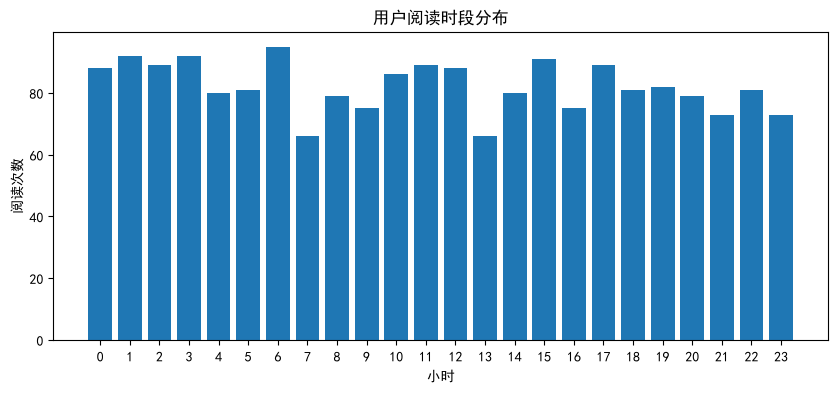

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 读取【当前目录】下的csv（不是data/raw）
df_user = pd.read_csv("user.csv", encoding="utf-8-sig")
df_novel = pd.read_csv("novel.csv", encoding="utf-8-sig")
df_read = pd.read_csv("read_record.csv", encoding="utf-8-sig")
df_collect = pd.read_csv("collect.csv", encoding="utf-8-sig")
df_comment = pd.read_csv("comment.csv", encoding="utf-8-sig")

# ---------------------- 查看基础信息 ----------------------
print("===阅读记录原始数据概况===")
print(df_read.info())
print("异常阅读时长统计：")
print(df_read["read_duration"].value_counts().sort_index())

# ---------------------- 数据清洗（面试重点！） ----------------------
df_read_clean = df_read.copy()
# 1. 删除阅读时长<=0的异常记录
df_read_clean = df_read_clean[df_read_clean["read_duration"] > 0]

# 2. 时间转datetime，方便判断间隔
df_read_clean["read_start_time"] = pd.to_datetime(df_read_clean["read_start_time"])
# 排序
df_read_clean = df_read_clean.sort_values(["user_id","novel_id","read_start_time"])
# 3. 去重：同一用户同一本书，40秒内多条记录只保留第一条
df_read_clean["time_diff"] = df_read_clean.groupby(["user_id","novel_id"])["read_start_time"].diff()
df_read_clean = df_read_clean[(df_read_clean["time_diff"].isna()) | (df_read_clean["time_diff"] > pd.Timedelta(seconds=40))]
df_read_clean = df_read_clean.drop("time_diff", axis=1)

# 4. 评论表清洗：空内容标记为【无文字评论】
df_comment_clean = df_comment.copy()
df_comment_clean["comment_content"] = df_comment_clean["comment_content"].replace("", "无文字评论")

# 保存清洗后数据（先直接放当前目录测试）
df_read_clean.to_csv("read_record_clean.csv", index=False, encoding="utf-8-sig")
df_comment_clean.to_csv("comment_clean.csv", index=False, encoding="utf-8-sig")
print("✅ 清洗完成，已保存清洗后csv")

# ---------------------- 简单指标计算 & 绘图示例 ----------------------
# 新增日期列
df_read_clean["dt"] = df_read_clean["read_start_time"].dt.date
# 计算DAU
dau_df = df_read_clean.groupby("dt")["user_id"].nunique().reset_index(name="dau")

plt.figure(figsize=(12,4))
plt.plot(dau_df["dt"], dau_df["dau"], marker='o')
plt.title("平台每日DAU趋势")
plt.xlabel("日期")
plt.ylabel("DAU（独立用户数）")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 阅读时段分布
df_read_clean["hour"] = df_read_clean["read_start_time"].dt.hour
hour_cnt = df_read_clean.groupby("hour").size()
plt.figure(figsize=(10,4))
plt.bar(hour_cnt.index, hour_cnt.values)
plt.title("用户阅读时段分布")
plt.xlabel("小时")
plt.ylabel("阅读次数")
plt.xticks(range(0,24))
plt.show()


In [3]:
import pandas as pd
import numpy as np
import random
from datetime import datetime, timedelta

# 设置随机种子，保证每次运行结果一致
np.random.seed(42)
random.seed(42)

# ---------------------- 1. user表 ----------------------
user_count = 300
user_ids = list(range(1, user_count + 1))
register_start = datetime(2026, 1, 1)
register_end = datetime(2026, 4, 30)

def random_date(start, end):
    delta = end - start
    return start + timedelta(seconds=random.randint(0, int(delta.total_seconds())))

user_type_list = ["注册用户", "游客"]
user_data = []
for uid in user_ids:
    rt = random_date(register_start, register_end)
    ut = np.random.choice(user_type_list, p=[0.65, 0.35])
    user_data.append({
        "user_id": uid,
        "register_time": rt.strftime("%Y-%m-%d %H:%M:%S"),
        "user_type": ut
    })
df_user = pd.DataFrame(user_data)
df_user.to_csv("user.csv", index=False, encoding="utf-8-sig")
print("✅ user.csv 生成完成")

# ---------------------- 2. novel作品表 ----------------------
novel_count = 80
novel_ids = list(range(1, novel_count + 1))
cate_list = ["玄幻", "言情", "都市", "悬疑", "科幻"]
novel_data = []
for nid in novel_ids:
    ct = random_date(datetime(2026,1,1), datetime(2026,4,20))
    category = random.choice(cate_list)
    novel_data.append({
        "novel_id": nid,
        "title": f"{category}小说_{nid}",
        "category": category,
        "create_time": ct.strftime("%Y-%m-%d %H:%M:%S")
    })
df_novel = pd.DataFrame(novel_data)
df_novel.to_csv("novel.csv", index=False, encoding="utf-8-sig")
print("✅ novel.csv 生成完成")

# ---------------------- 3. read_record阅读记录表（重点，内置脏数据） ----------------------
record_total = 2200
read_data = []
read_start_dt = datetime(2026, 2, 1)
read_end_dt = datetime(2026, 4, 30)

for _ in range(record_total):
    uid = random.choice(user_ids)
    nid = random.choice(novel_ids)
    st = random_date(read_start_dt, read_end_dt)
    # 制造脏数据：一部分时长=0、负数
    r_duration = np.random.choice(
        [0, -10, random.randint(30, 3600)],
        p=[0.07, 0.03, 0.90]
    )
    read_data.append({
        "record_id": len(read_data)+1,
        "user_id": uid,
        "novel_id": nid,
        "read_start_time": st.strftime("%Y-%m-%d %H:%M:%S"),
        "read_duration": r_duration
    })
# 额外加一批【重复记录脏数据】：同一个用户短时间多次刷同一本书
dup_count = 120
base_records = random.sample(read_data, dup_count)
for r in base_records:
    t = datetime.strptime(r["read_start_time"], "%Y-%m-%d %H:%M:%S")
    new_t = t + timedelta(seconds=random.randint(10,40))
    read_data.append({
        "record_id": len(read_data)+1,
        "user_id": r["user_id"],
        "novel_id": r["novel_id"],
        "read_start_time": new_t.strftime("%Y-%m-%d %H:%M:%S"),
        "read_duration": r["read_duration"]
    })

df_read = pd.DataFrame(read_data)
df_read.to_csv("read_record.csv", index=False, encoding="utf-8-sig")
print("✅ read_record.csv 生成完成（包含重复、时长0、负数脏数据）")

# ---------------------- 4. collect收藏表 ----------------------
collect_data = []
collect_cnt = 650
for _ in range(collect_cnt):
    uid = random.choice(user_ids)
    nid = random.choice(novel_ids)
    ct = random_date(datetime(2026,2,1), datetime(2026,4,30))
    collect_data.append({
        "collect_id": len(collect_data)+1,
        "user_id": uid,
        "novel_id": nid,
        "collect_time": ct.strftime("%Y-%m-%d %H:%M:%S")
    })
df_collect = pd.DataFrame(collect_data)
df_collect.to_csv("collect.csv", index=False, encoding="utf-8-sig")
print("✅ collect.csv 生成完成")

# ---------------------- 5. comment评论表（包含空评论脏数据） ----------------------
comment_data = []
comment_cnt = 400
comment_text_pool = ["写得很好", "期待后续更新", "有点慢", "好看！", ""]
for _ in range(comment_cnt):
    uid = random.choice(user_ids)
    nid = random.choice(novel_ids)
    ct = random_date(datetime(2026,2,1), datetime(2026,4,30))
    content = random.choice(comment_text_pool)
    comment_data.append({
        "comment_id": len(comment_data)+1,
        "user_id": uid,
        "novel_id": nid,
        "comment_content": content,
        "create_time": ct.strftime("%Y-%m-%d %H:%M:%S")
    })
df_comment = pd.DataFrame(comment_data)
df_comment.to_csv("comment.csv", index=False, encoding="utf-8-sig")
print("✅ comment.csv 生成完成（包含空评论脏数据）")

print("\n🎉 全部5张CSV生成完毕！")


✅ user.csv 生成完成
✅ novel.csv 生成完成
✅ read_record.csv 生成完成（包含重复、时长0、负数脏数据）
✅ collect.csv 生成完成
✅ comment.csv 生成完成（包含空评论脏数据）

🎉 全部5张CSV生成完毕！
